# S30 - EA3 Unidad 2 - Aprendizaje supervisado y no supervisado

Notebook de **evidencias**. Usa las mismas clases y la misma configuración (`src/config.py`) que
`main.py`, el script que ejecuta GitHub Actions.

```
Pregunta de negocio
        ↓
Hugging Face → DataFrame → preprocesamiento
                         → modelo supervisado (Random Forest)
                         → métricas y evaluación
                         → resumen automático .txt + gráficas
                         → documento de hallazgos (HALLAZGOS.md)
```

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

warnings.filterwarnings("ignore")
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import config
from src.pipeline import FEATURES, build_preprocessor, load_raw_data, run_experiment
from src.preprocessing import split_and_build_target
from src.report_writer import RunSummaryWriter
from main import make_figures

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
FIGURES = PROJECT_ROOT / config.FIGURES_DIR
print("Semilla:", config.RANDOM_STATE, "| test_size:", config.TEST_SIZE, "| pliegues CV:", config.CV_FOLDS)

Semilla: 42 | test_size: 0.3 | pliegues CV: 5


## 0. Pregunta de negocio y DataFrame

**Pregunta:** ¿Qué características de un alojamiento de Airbnb en Londres hacen que su precio de fin
de semana quede **por encima de la mediana del mercado**? La respuesta sirve para fijar el precio
de un anuncio y decidir en qué mejoras invertir.

- **Quién la necesita:** anfitriones de Airbnb en Londres y las agencias que gestionan alojamientos
  por ellos, en particular su equipo de precios.
- **Qué decisión apoya:**
  - ubicar un anuncio nuevo en la gama alta o en la estándar;
  - detectar anuncios que podrían cobrar más;
  - priorizar inversiones (capacidad, habitaciones, calidad del servicio) según su efecto en el
    precio.

**Por qué sirve este dataset:** `kraina/airbnb_london_weekends` contiene **5 379 anuncios reales**
de Airbnb en Londres para fin de semana. Proviene del estudio académico de Gyódi y Nawaro (2021),
publicado en *Tourism Management*. Cada anuncio tiene:
- su precio (`realSum`: precio total de la estancia en €, para 2 personas y 2 noches según el
  estudio original);
- sus características (tipo de alojamiento, capacidad, habitaciones, calificaciones);
- su ubicación (distancia al centro y al metro, índices de atracciones y restaurantes cercanos).

Son justamente los factores que un anfitrión puede conocer o modificar.

In [2]:
df_raw = load_raw_data()
print("Dataset:", config.DATASET_ID, "| split:", config.DATASET_SPLIT)
print("Tamaño (filas, columnas):", df_raw.shape)
print("Columnas:", list(df_raw.columns))
df_raw.dtypes

Dataset: kraina/airbnb_london_weekends | split: train
Tamaño (filas, columnas): (5379, 18)
Columnas: ['_id', 'realSum', 'room_type', 'room_shared', 'room_private', 'person_capacity', 'host_is_superhost', 'multi', 'biz', 'cleanliness_rating', 'guest_satisfaction_overall', 'bedrooms', 'dist', 'metro_dist', 'attr_index', 'attr_index_norm', 'rest_index', 'rest_index_norm']


_id                               str
realSum                       float64
room_type                         str
room_shared                      bool
room_private                     bool
person_capacity               float64
host_is_superhost                bool
multi                           int64
biz                             int64
cleanliness_rating            float64
guest_satisfaction_overall    float64
bedrooms                        int64
dist                          float64
metro_dist                    float64
attr_index                    float64
attr_index_norm               float64
rest_index                    float64
rest_index_norm               float64
dtype: object

In [3]:
df_raw.head()

,_id,realSum,room_type,room_shared,room_private,person_capacity,host_is_superhost,multi,biz,cleanliness_rating,guest_satisfaction_overall,bedrooms,dist,metro_dist,attr_index,attr_index_norm,rest_index,rest_index_norm
0,10936,121.122322,Private room,False,True,2.0,False,0,0,6.0,69.0,1,5.734117,0.437094,222.882243,15.493414,470.088502,8.413765
1,10937,195.912416,Private room,False,True,2.0,False,1,0,10.0,96.0,1,4.788905,1.464050,235.385841,16.362588,530.133525,9.488466
2,10938,193.325337,Private room,False,True,3.0,False,1,0,10.0,95.0,1,4.596677,0.450306,268.913812,18.693247,548.987610,9.825922
3,10939,180.389943,Private room,False,True,2.0,False,1,0,9.0,87.0,1,2.054769,0.132670,472.381314,32.837067,1021.271062,18.278973
4,10940,405.700981,Entire home/apt,False,False,3.0,False,0,1,7.0,65.0,0,4.491277,0.354108,318.491470,22.139584,692.775411,12.399473


In [4]:
df_raw.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
realSum,5379.0,364.39,437.74,54.33,174.51,268.12,438.27,12937.28
person_capacity,5379.0,2.86,1.25,2.00,2.00,2.00,4.00,6.00
multi,5379.0,0.28,0.45,0.00,0.00,0.00,1.00,1.00
biz,5379.0,0.36,0.48,0.00,0.00,0.00,1.00,1.00
cleanliness_rating,5379.0,9.19,1.15,2.00,9.00,10.00,10.00,10.00
guest_satisfaction_overall,5379.0,90.92,11.29,20.00,87.00,94.00,99.00,100.00
bedrooms,5379.0,1.13,0.58,0.00,1.00,1.00,1.00,8.00
dist,5379.0,5.33,2.71,0.04,3.55,4.94,6.84,17.32
metro_dist,5379.0,1.02,1.27,0.01,0.32,0.54,1.09,9.17
attr_index,5379.0,294.58,170.52,68.74,177.22,247.65,361.07,1438.56


## 1. Preprocesamiento

### 1.1 Estado inicial: nulos, duplicados y redundancias

In [5]:
print("Nulos totales:", int(df_raw.isnull().sum().sum()))
print("Duplicados (sin contar _id):", int(df_raw.drop(columns="_id").duplicated().sum()))
print()
print("Correlación attr_index vs attr_index_norm:", round(df_raw.attr_index.corr(df_raw.attr_index_norm), 4))
print("Correlación rest_index vs rest_index_norm:", round(df_raw.rest_index.corr(df_raw.rest_index_norm), 4))
print()
print("room_type vs room_shared / room_private (información repetida):")
display(pd.crosstab(df_raw.room_type, [df_raw.room_shared, df_raw.room_private]))
print("multi vs biz (nunca valen 1 a la vez):")
pd.crosstab(df_raw.multi, df_raw.biz)

Nulos totales: 0
Duplicados (sin contar _id): 0

Correlación attr_index vs attr_index_norm: 1.0
Correlación rest_index vs rest_index_norm: 1.0

room_type vs room_shared / room_private (información repetida):


room_shared     False       True 
room_private    False True  False
room_type                        
Entire home/apt  2418     0     0
Private room        0  2934     0
Shared room         0     0    27

multi vs biz (nunca valen 1 a la vez):


biz,0,1
multi,,
0,1949,1925
1,1505,0


### 1.2 Limpieza y enriquecimiento (`ListingPreprocessor.clean`)

Estas operaciones **no aprenden de los datos**, así que pueden aplicarse antes de dividir:

1. **Eliminar columnas redundantes:**
   - `_id`: es un identificador.
   - `room_shared` y `room_private`: repiten `room_type`.
   - `attr_index_norm` y `rest_index_norm`: son reescalados con correlación 1.0.
2. **Enriquecer:** `multi` (2–4 anuncios) y `biz` (más de 4) son excluyentes y se unen en una sola
   variable categórica, `host_type`.
3. **Nulos y duplicados:** no hay, pero se controlan.
4. **Corregir tipos:**
   - `host_is_superhost` pasa de verdadero/falso a 0/1;
   - las numéricas pasan a `float`;
   - `room_type` y `host_type` pasan a categóricas.

In [6]:
preprocessor = build_preprocessor()
df_clean = preprocessor.clean(df_raw)
preprocessor.steps_as_dataframe()

,operation,reason,effect
0,Eliminar columnas redundantes,"_id: identificador del anuncio, no describe el alojamiento; room_shared: repite room_type (Shared room); room_privat...",18 -> 13 columnas.
1,Enriquecer: tipo de anfitrión,multi y biz son excluyentes (casos con ambas en 1: 0); juntas describen un solo dato.,"multi + biz -> host_type: {'particular (1 anuncio)': 1949, 'empresa (>4 anuncios)': 1925, 'multi (2-4 anuncios)': 15..."
2,Nulos y duplicados,Un anuncio repetido en train y test inflaría las métricas.,Nulos: 0; duplicados: 0; filas: 5379 -> 5379.
3,Corregir tipos,Los modelos de scikit-learn requieren números; las categorías se codifican después dentro del Pipeline.,"host_is_superhost: bool -> 0/1; numéricas -> float; ['room_type', 'host_type'] -> 'category'."


In [7]:
pd.DataFrame({
    "antes": [df_raw.shape[0], df_raw.shape[1], "multi, biz (0/1)", str(df_raw.host_is_superhost.dtype),
              str(df_raw.room_type.dtype), "sí"],
    "después": [df_clean.shape[0], df_clean.shape[1], "host_type (3 categorías)",
                str(df_clean.host_is_superhost.dtype), str(df_clean.room_type.dtype), "no"],
}, index=["filas", "columnas", "tipo de anfitrión", "host_is_superhost", "room_type", "¿columnas redundantes?"])

,antes,después
filas,5379,5379
columnas,18,12
tipo de anfitrión,"multi, biz (0/1)",host_type (3 categorías)
host_is_superhost,bool,float64
room_type,str,category
¿columnas redundantes?,sí,no


In [8]:
df_clean.head()

,realSum,room_type,person_capacity,host_is_superhost,cleanliness_rating,guest_satisfaction_overall,bedrooms,dist,metro_dist,attr_index,rest_index,host_type
0,121.122322,Private room,2.0,0.0,6.0,69.0,1.0,5.734117,0.437094,222.882243,470.088502,particular (1 anuncio)
1,195.912416,Private room,2.0,0.0,10.0,96.0,1.0,4.788905,1.464050,235.385841,530.133525,multi (2-4 anuncios)
2,193.325337,Private room,3.0,0.0,10.0,95.0,1.0,4.596677,0.450306,268.913812,548.987610,multi (2-4 anuncios)
3,180.389943,Private room,2.0,0.0,9.0,87.0,1.0,2.054769,0.132670,472.381314,1021.271062,multi (2-4 anuncios)
4,405.700981,Entire home/apt,3.0,0.0,7.0,65.0,0.0,4.491277,0.354108,318.491470,692.775411,empresa (>4 anuncios)


### 1.3 Variable objetivo, división y codificación sin fuga

- **Variable objetivo construida:** `precio_alto` = 1 si `realSum` supera la **mediana de
  entrenamiento**, y 0 en caso contrario.
  - La mediana se calcula **solo con entrenamiento** y se aplica igual a prueba.
  - Así las dos clases quedan equilibradas, y el resultado no depende de unos pocos precios
    extremos (el máximo es más de 40 veces la mediana).
  - `realSum` **no** se usa como predictora, porque de ella sale la respuesta.
- **División:** 70 % entrenamiento / 30 % prueba, con `random_state=42`.
- **Codificación:** `OneHotEncoder` para `room_type` y `host_type`, dentro del `Pipeline` del modelo,
  así que aprende las categorías solo con entrenamiento.
- **Sin escalado:** Random Forest compara cada variable con umbrales ("¿capacidad > 3?"), así que la
  escala no cambia nada. En cambio, los métodos basados en distancias (KNN, SVM) **sí se escalaron**
  en la comparación de la sección 2.

In [9]:
X_train, X_test, y_train, y_test, median = split_and_build_target(
    df_clean, FEATURES, config.PRICE_COLUMN, config.TEST_SIZE, config.RANDOM_STATE)
print(f"Mediana de entrenamiento: €{median:.2f}")
print("Tamaños: entrenamiento", X_train.shape, "| prueba", X_test.shape)
print("Variables predictoras:", FEATURES)
pd.DataFrame({"entrenamiento": y_train.value_counts(normalize=True).round(3),
              "prueba": y_test.value_counts(normalize=True).round(3)}).rename(index=config.CLASS_NAMES)

Mediana de entrenamiento: €262.94
Tamaños: entrenamiento (3765, 11) | prueba (1614, 11)
Variables predictoras: ['person_capacity', 'bedrooms', 'cleanliness_rating', 'guest_satisfaction_overall', 'dist', 'metro_dist', 'attr_index', 'rest_index', 'host_is_superhost', 'room_type', 'host_type']


,entrenamiento,prueba
precio_alto,,
estándar,0.501,0.472
alto,0.499,0.528


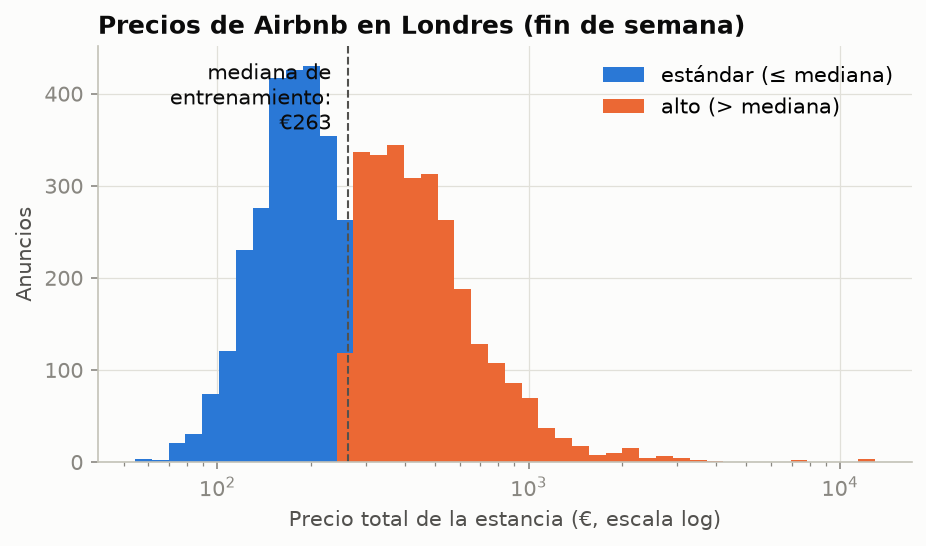

In [10]:
display(Image(FIGURES / "01_distribucion_precios.png"))

## 2. Selección del modelo

**Tipo de aprendizaje: supervisado (clasificación binaria).** La pregunta pide explicar y predecir
una variable **conocida**, el nivel de precio de cada anuncio. Un modelo no supervisado agruparía
los anuncios, pero no diría qué los hace caros.

Se comparan seis algoritmos con la **misma** validación cruzada estratificada de 5 pliegues, solo
sobre entrenamiento. El criterio es el **AUC ROC**, que mide qué tan bien separa el modelo los
anuncios caros de los estándar sin depender de un umbral.

Esta comparación, la búsqueda de hiperparámetros y la evaluación las ejecuta `run_experiment()`,
el mismo flujo de GitHub Actions. Las celdas siguientes muestran cada resultado intermedio.

In [11]:
results = run_experiment()
assert np.isclose(results.median_price, median)
assert results.X_test.index.equals(X_test.index)
print("El flujo automático usa exactamente la misma mediana y la misma división que este notebook.")
results.comparison.round(4)

El flujo automático usa exactamente la misma mediana y la misma división que este notebook.


,algoritmo,escalado,exactitud_cv,f1_cv,auc_cv
0,Random Forest,no,0.8733,0.8696,0.9368
1,Regresión logística,sí,0.8592,0.8537,0.9270
2,SVM (kernel RBF),sí,0.8622,0.8560,0.9245
3,KNN (k=15),sí,0.8637,0.8613,0.9207
4,Naive Bayes gaussiano,sí,0.8175,0.8331,0.9116
5,Árbol de decisión (prof. 6),no,0.8529,0.8468,0.9085


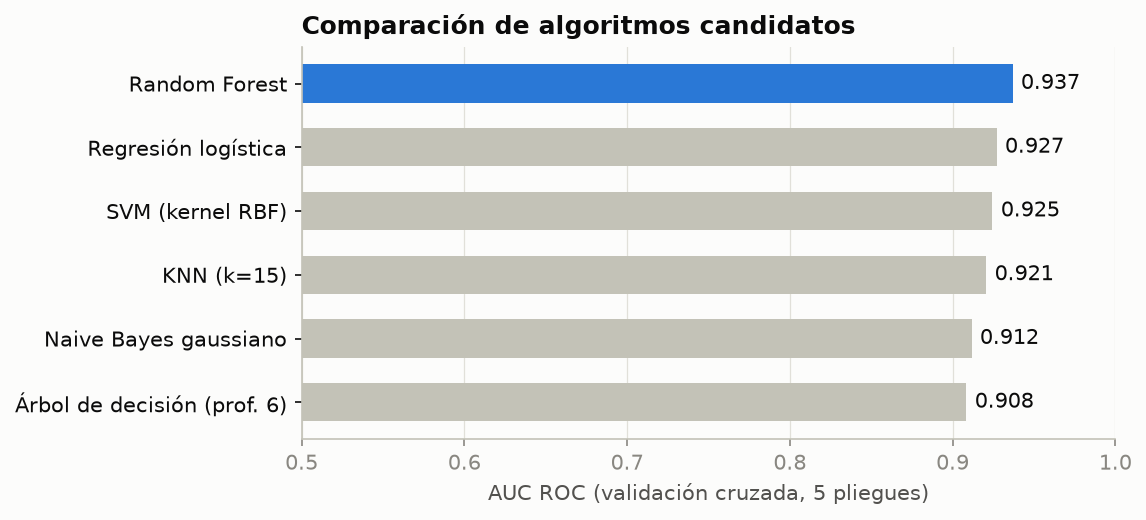

In [12]:
display(Image(FIGURES / "02_comparacion_algoritmos.png"))

**Random Forest obtiene el mejor AUC.** Además:
- No necesita escalar los datos.
- Capta relaciones no lineales; por ejemplo, el efecto de la capacidad no es constante.
- Capta interacciones; por ejemplo, la ubicación pesa distinto según el tipo de alojamiento.
- Permite medir qué variables influyen más en el precio, que es justo lo que pregunta el negocio.

El funcionamiento paso a paso se explica en el README.

## 3. Entrenamiento, hiperparámetros y evaluación

### 3.1 Búsqueda de hiperparámetros (`GridSearchCV`, AUC, 5 pliegues)

| Parámetro | Qué controla | Valores probados |
|---|---|---|
| `n_estimators` | Número de árboles que votan | 100, 300 |
| `max_depth` | Profundidad máxima de cada árbol (complejidad) | 4, 8, 12, sin límite |
| `min_samples_leaf` | Mínimo de anuncios en cada hoja (evita reglas para casos únicos) | 1, 5, 10 |
| `max_features` | Variables candidatas en cada división (diversidad entre árboles) | `sqrt`, 50 % |

In [13]:
print("Mejor combinación:", results.best_params)
results.model.grid_results.head(10).round(4)

Mejor combinación: {'max_depth': 12, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 300, 'score_cv': 0.9382788249901235}


,n_estimators,max_depth,min_samples_leaf,max_features,score_cv,score_cv_std
25,300,12,1,sqrt,0.9383,0.0057
24,100,12,1,sqrt,0.9380,0.0056
13,300,8,1,sqrt,0.9376,0.0065
12,100,8,1,sqrt,0.9375,0.0060
19,300,8,1,0.5,0.9372,0.0056
27,300,12,5,sqrt,0.9370,0.0063
15,300,8,5,sqrt,0.9368,0.0069
39,300,None,5,sqrt,0.9367,0.0065
37,300,None,1,sqrt,0.9366,0.0059
18,100,8,1,0.5,0.9365,0.0059


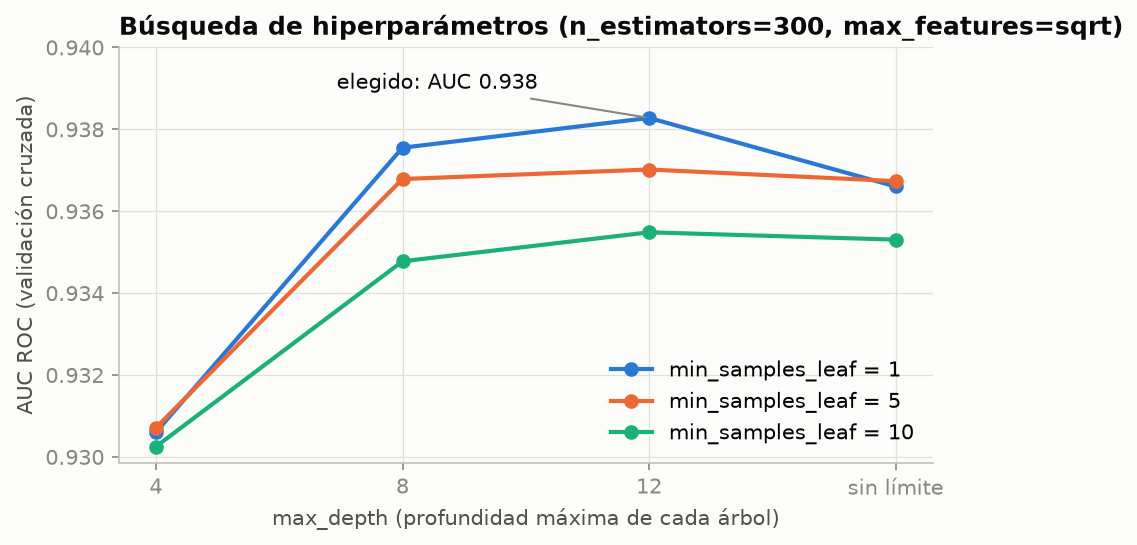

In [14]:
display(Image(FIGURES / "03_busqueda_hiperparametros.png"))

- Con árboles de profundidad 4 el modelo se queda corto.
- A partir de profundidad 8 el AUC se estabiliza, y la profundidad 12 da el mejor resultado.
- Sin límite de profundidad no mejora: los árboles empiezan a memorizar casos.
- Las diferencias entre las mejores combinaciones son pequeñas (menos de 0.01 de AUC), así que el
  modelo es **robusto** a estos parámetros.

### 3.2 Evaluación en prueba

In [15]:
m = results.metrics
pd.Series({"exactitud": m["accuracy"], "referencia (adivinar la clase mayoritaria)": m["baseline_accuracy"],
           "precisión (alto)": m["precision"], "recall (alto)": m["recall"], "F1 (alto)": m["f1"],
           "AUC ROC": m["roc_auc"]}).round(4)

exactitud                                     0.8748
referencia (adivinar la clase mayoritaria)    0.5279
precisión (alto)                              0.9124
recall (alto)                                 0.8439
F1 (alto)                                     0.8768
AUC ROC                                       0.9460
dtype: float64

In [16]:
print(m["report_text"])
m["confusion_matrix"]

              precision    recall  f1-score   support

    estándar      0.839     0.909     0.873       762
        alto      0.912     0.844     0.877       852

    accuracy                          0.875      1614
   macro avg      0.876     0.877     0.875      1614
weighted avg      0.878     0.875     0.875      1614



,pred_estándar,pred_alto
real_estándar,693,69
real_alto,133,719


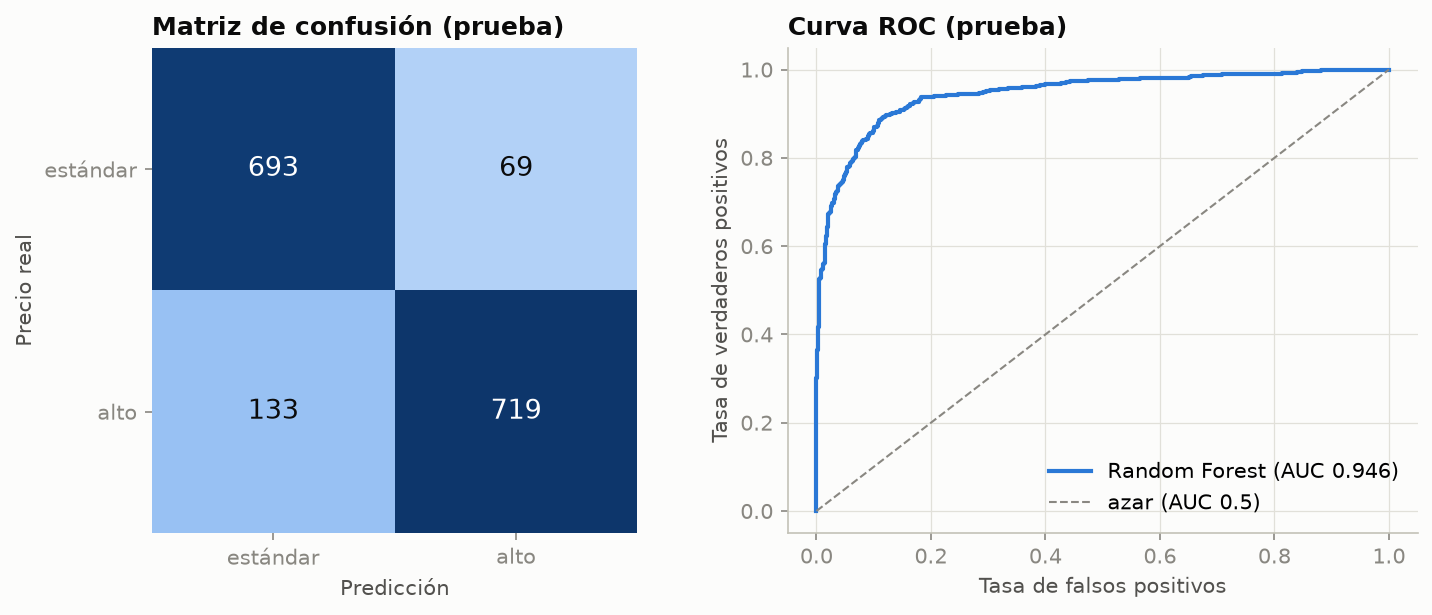

In [17]:
display(Image(FIGURES / "04_matriz_confusion_roc.png"))

**Por qué estas métricas:**
- Las clases están **equilibradas** (alrededor de 50 / 50, porque el corte es la mediana), así que la
  **exactitud** es representativa.
- Se reportan **precisión** y **recall** de la clase "alto" porque los dos errores cuestan distinto:
  - **Falso "alto"** (precisión): el modelo dice que el anuncio puede ser caro, pero es estándar. Si
    el anfitrión sube el precio, se arriesga a quedarse sin reservas. **Es el error más costoso**, y
    el modelo lo comete poco (precisión del 91 %).
  - **Falso "estándar"** (recall): el modelo no detecta un anuncio caro, y el anfitrión deja dinero
    sobre la mesa. Este error es más frecuente: el recall es del 84 %, así que se escapan 16 de cada
    100 anuncios caros.
- El **AUC** resume la capacidad de separar las dos clases con cualquier umbral.

In [18]:
# Anuncios de prueba mal clasificados con más seguridad
errors = df_clean.loc[results.X_test.index, FEATURES + [config.PRICE_COLUMN]].copy()
errors["real"] = results.y_test.map(config.CLASS_NAMES)
errors["P(alto)"] = results.model.predict_proba(results.X_test).round(3)
errors["predicho"] = pd.Series(results.model.predict(results.X_test), index=errors.index).map(config.CLASS_NAMES)
wrong = errors[errors.real != errors.predicho]
print("Errores en prueba:", len(wrong), "de", len(errors))
display(wrong.groupby(["real", "room_type"], observed=True).size().rename("errores").to_frame())
wrong.assign(seguridad=(wrong["P(alto)"] - 0.5).abs()).sort_values("seguridad", ascending=False).head(8)

Errores en prueba: 202 de 1614


errores
real     room_type               
alto     Entire home/apt        7
         Private room         125
         Shared room            1
estándar Entire home/apt       55
         Private room          14

,person_capacity,bedrooms,cleanliness_rating,guest_satisfaction_overall,dist,metro_dist,attr_index,rest_index,host_is_superhost,room_type,host_type,realSum,real,P(alto),predicho,seguridad
1566,2.0,1.0,10.0,96.0,4.793476,0.243922,271.661286,652.494041,0.0,Entire home/apt,particular (1 anuncio),257.767116,estándar,0.982,alto,0.482
2372,2.0,1.0,9.0,92.0,6.751112,1.737293,163.143870,343.124529,0.0,Private room,multi (2-4 anuncios),298.925186,alto,0.023,estándar,0.477
4807,4.0,1.0,9.0,95.0,4.650537,0.230222,238.554791,545.877610,0.0,Entire home/apt,particular (1 anuncio),239.187187,estándar,0.972,alto,0.472
1121,2.0,1.0,10.0,100.0,9.760083,0.808113,116.005155,253.341181,1.0,Private room,multi (2-4 anuncios),322.208895,alto,0.029,estándar,0.471
1375,2.0,1.0,10.0,98.0,7.328568,3.335514,165.937879,325.551867,0.0,Private room,empresa (>4 anuncios),296.573297,alto,0.033,estándar,0.467
679,3.0,1.0,10.0,93.0,14.841893,6.481093,81.769813,166.354896,0.0,Private room,multi (2-4 anuncios),499.776570,alto,0.033,estándar,0.467
4410,2.0,1.0,10.0,100.0,7.845434,2.795140,147.262514,316.498143,0.0,Private room,particular (1 anuncio),310.214257,alto,0.034,estándar,0.466
5261,2.0,1.0,10.0,97.0,5.898178,2.410152,196.279762,434.124352,0.0,Private room,empresa (>4 anuncios),265.293163,alto,0.036,estándar,0.464


### 3.3 ¿Qué determina que un anuncio sea de precio alto?

In [19]:
results.importance.assign(variable=results.importance.variable.map(config.FEATURE_LABELS)).round(4)

,variable,importancia,desviacion
0,tipo de alojamiento,0.2323,0.0072
1,índice de restaurantes cercanos,0.0305,0.0026
2,capacidad (personas),0.0220,0.0020
3,habitaciones,0.0099,0.0016
4,índice de atracciones cercanas,0.0084,0.0012
5,distancia al metro (km),0.0077,0.0011
6,calificación de limpieza (0-10),0.0057,0.0008
7,distancia al centro (km),0.0045,0.0014
8,tipo de anfitrión,0.0043,0.0009
9,satisfacción de huéspedes (0-100),0.0035,0.0011


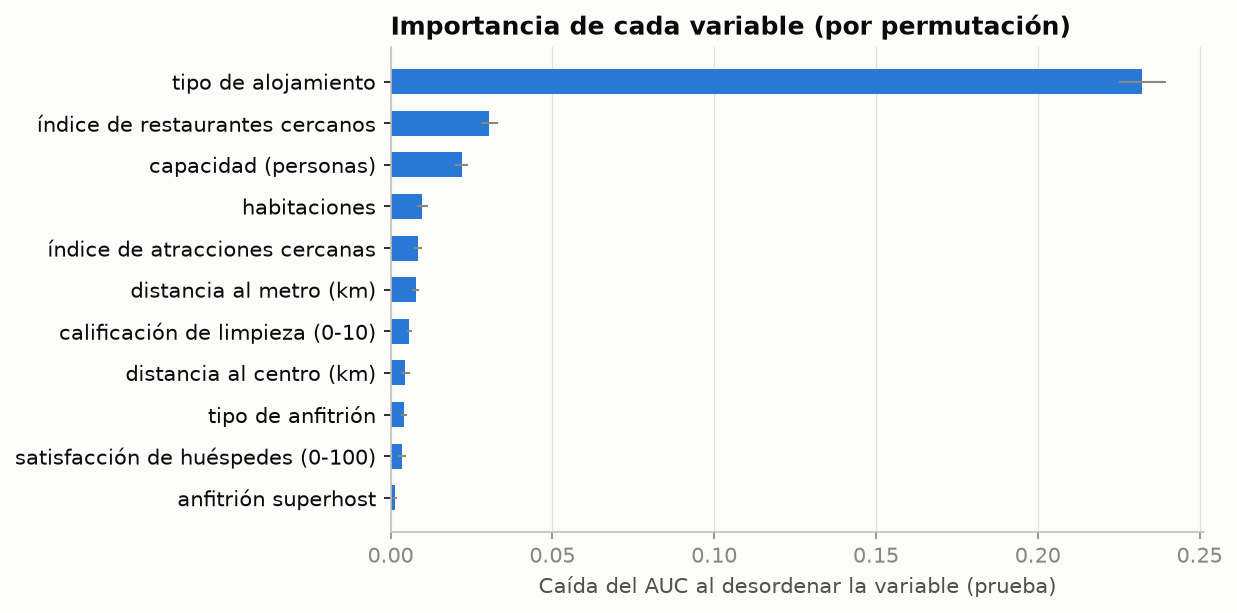

In [20]:
display(Image(FIGURES / "05_importancia_variables.png"))

La **importancia por permutación** mide cuánto empeora el AUC en prueba si se desordena una
variable al azar. Cuanto más empeora, más depende el modelo de ella. Se calcula en **prueba**, con
datos que el modelo no vio.

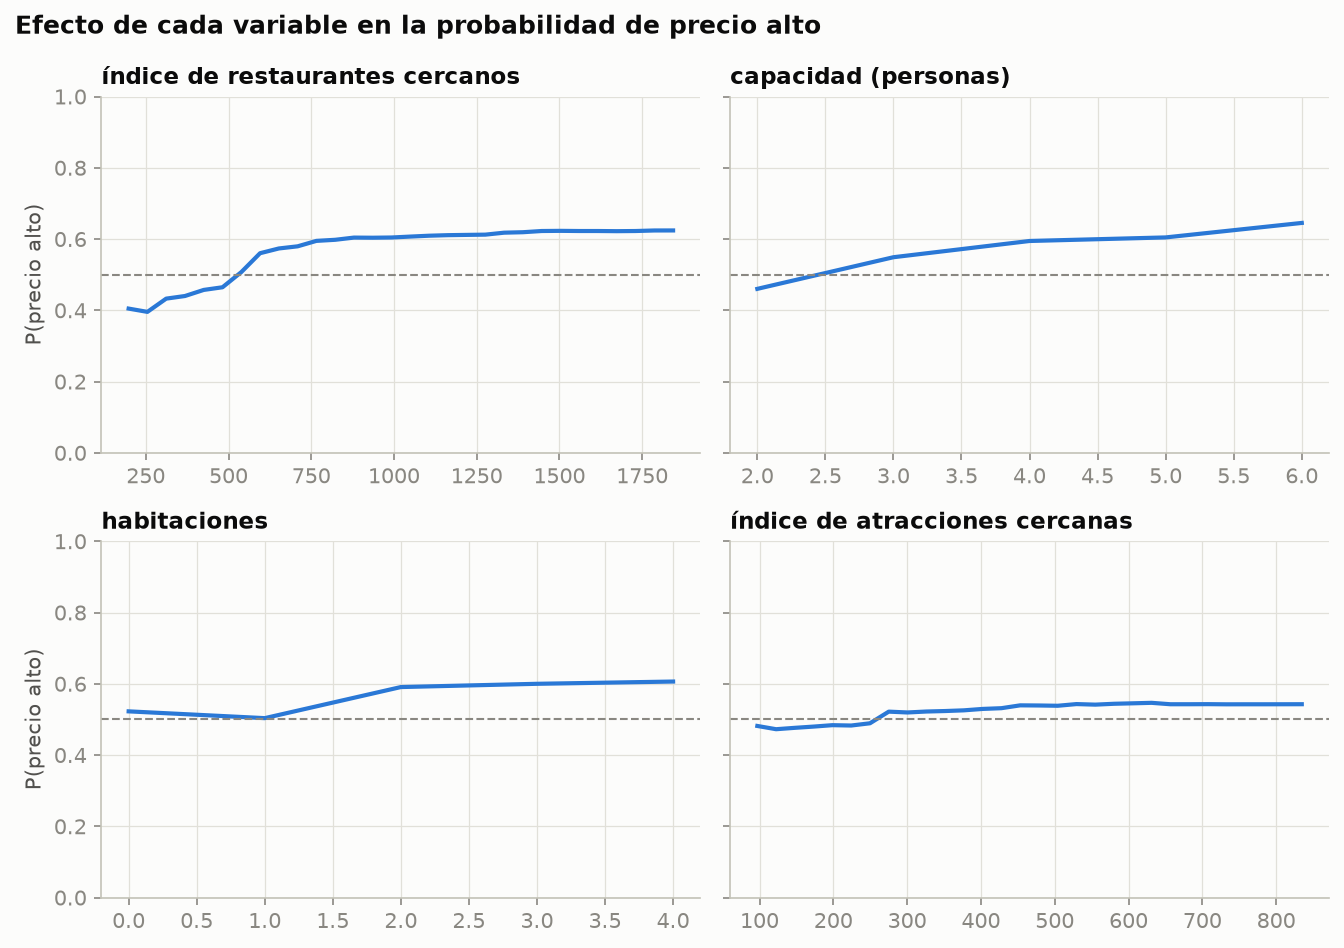

In [21]:
display(Image(FIGURES / "06_dependencia_parcial.png"))

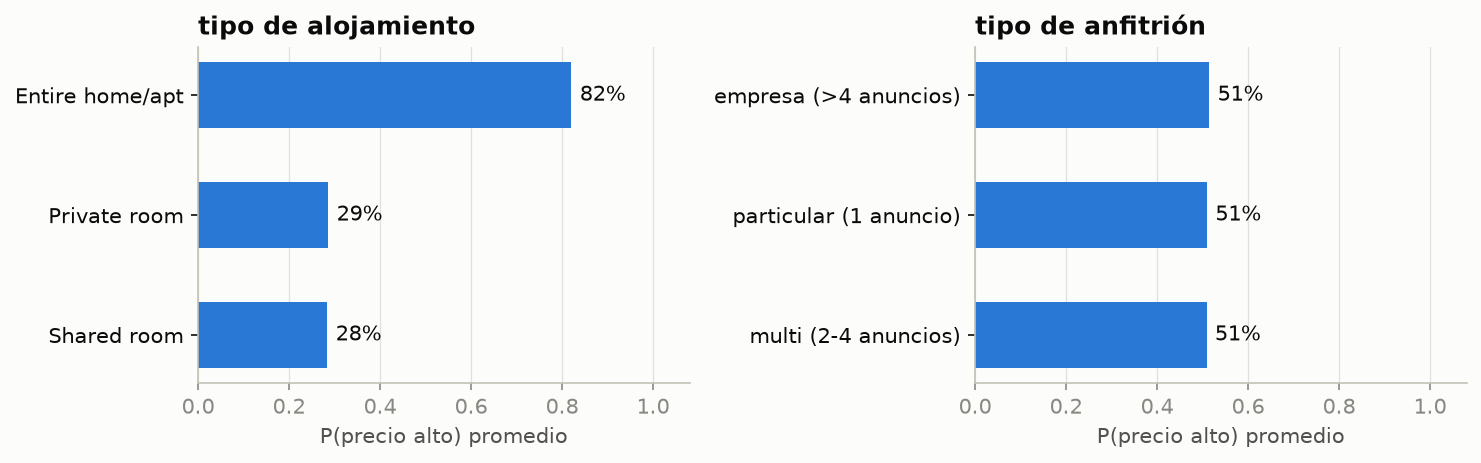

In [22]:
display(Image(FIGURES / "07_efecto_categorias.png"))

In [23]:
for feature, data in results.dependence.items():
    print(f"{config.FEATURE_LABELS[feature]}: P(alto) {data.probabilidad.iloc[0]:.2f} -> {data.probabilidad.iloc[-1]:.2f} "
          f"(de {data.valor.iloc[0]:.1f} a {data.valor.iloc[-1]:.1f})")
for feature, series in results.category_effects.items():
    print(config.FEATURE_LABELS[feature] + ":", {k: round(v, 2) for k, v in series.items()})

índice de restaurantes cercanos: P(alto) 0.40 -> 0.62 (de 198.2 a 1843.4)
capacidad (personas): P(alto) 0.46 -> 0.65 (de 2.0 a 6.0)
habitaciones: P(alto) 0.52 -> 0.61 (de 0.0 a 4.0)
índice de atracciones cercanas: P(alto) 0.48 -> 0.54 (de 97.0 a 834.7)
tipo de alojamiento: {'Entire home/apt': 0.82, 'Private room': 0.29, 'Shared room': 0.28}
tipo de anfitrión: {'empresa (>4 anuncios)': 0.51, 'particular (1 anuncio)': 0.51, 'multi (2-4 anuncios)': 0.51}


- **Dependencia parcial:** cambia una sola variable en todos los anuncios de prueba, deja el resto
  igual, y promedia la probabilidad de precio alto. Muestra el **efecto aislado** de esa variable.
- **Efecto de categorías:** hace lo mismo con cada categoría de `room_type` y `host_type`.

La interpretación para el negocio está en **`HALLAZGOS.md`**.

## 4. Resumen automático `.txt` y gráficas

Se generan el resumen y las siete gráficas a partir de los resultados de `run_experiment()`.

In [24]:
figures = make_figures(results)
summary_path = RunSummaryWriter(results, figures).save(
    PROJECT_ROOT / config.OUTPUT_DIR / config.SUMMARY_FILENAME)
print("Resumen:", summary_path, "| existe:", summary_path.exists())
print("Gráficas:", [f.as_posix() for f in figures])

Resumen: C:\Proyectos\MachineLearningIU\S30_Unidad2_EA3_Aprendizaje_Supervisado_y_No_Supervisado\output\resumen_ejecucion.txt | existe: True
Gráficas: ['output/figuras/01_distribucion_precios.png', 'output/figuras/02_comparacion_algoritmos.png', 'output/figuras/03_busqueda_hiperparametros.png', 'output/figuras/04_matriz_confusion_roc.png', 'output/figuras/05_importancia_variables.png', 'output/figuras/06_dependencia_parcial.png', 'output/figuras/07_efecto_categorias.png']


In [25]:
print(summary_path.read_text(encoding="utf-8"))

S30 - EA3 UNIDAD 2 - APRENDIZAJE SUPERVISADO Y NO SUPERVISADO
Resumen generado automáticamente por código
Fecha de ejecución: 2026-11-07 23:06:03 (UTC-0500)
Entorno: Python 3.12.10 | pandas 3.1.0 | scikit-learn 1.9.1 | datasets 5.1.0

1. PREGUNTA DE NEGOCIO
Pregunta:  ¿Qué características de un alojamiento de Airbnb en Londres hacen que su precio de fin de semana quede por encima de la mediana del mercado, para fijar el precio de un anuncio y decidir en qué mejoras invertir?
Quién:     Anfitriones de Airbnb en Londres y agencias que gestionan alojamientos por ellos (equipo de precios).
Decisión:  Ubicar un anuncio en la gama de precio alta o estándar, detectar anuncios con potencial para cobrar más y priorizar inversiones (capacidad, habitaciones, calidad del servicio) según su efecto en el precio.

2. DATASET
Identificador: kraina/airbnb_london_weekends
Enlace:        https://huggingface.co/datasets/kraina/airbnb_london_weekends
Split:         train (único publicado)
Fuente original: 

## 5. Ejecución automática en GitHub Actions

El workflow `.github/workflows/s30_ea3_supervisado.yml` (en la raíz del repositorio) se activa con
cada **push** a `main` que modifique esta carpeta. Hace lo siguiente:

1. Instala Python 3.12 y `requirements.txt`.
2. Ejecuta `python main.py`, que descarga el dataset, preprocesa, compara algoritmos, ajusta
   hiperparámetros, entrena, evalúa, interpreta y genera el resumen y las gráficas.
3. Publica `resumen_ejecucion.txt` y las gráficas como **artefacto descargable** `resumen-ea3`.